# Geographic Choropleth Maps with GeoPandas

This tutorial creates reproducible world and regional choropleth maps from an archived Johns Hopkins COVID-19 snapshot and Natural Earth country boundaries.

# Step #1 Load a Fixed COVID-19 Snapshot

In [1]:
import country_converter as coco
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

COVID_URL = (
    "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/"
    "csse_covid_19_data/csse_covid_19_time_series/"
    "time_series_covid19_confirmed_global.csv"
 )
SNAPSHOT_COLUMN = "12/31/22"
PERIOD_START_COLUMN = "11/30/22"
NON_COUNTRY_ROWS = {
    "Diamond Princess",
    "MS Zaandam",
    "Summer Olympics 2020",
    "Winter Olympics 2022",
}

confirmed_raw = pd.read_csv(COVID_URL)
required_columns = {SNAPSHOT_COLUMN, PERIOD_START_COLUMN}
if not required_columns.issubset(confirmed_raw.columns):
    raise KeyError(f"Missing snapshot columns: {required_columns - set(confirmed_raw.columns)}")

country_cases = (
    confirmed_raw.loc[~confirmed_raw["Country/Region"].isin(NON_COUNTRY_ROWS)]
    .groupby("Country/Region", as_index=False)[[PERIOD_START_COLUMN, SNAPSHOT_COLUMN]]
    .sum()
    .rename(
        columns={
            PERIOD_START_COLUMN: "period_start_cases",
            SNAPSHOT_COLUMN: "total_cases",
        }
    )
)
country_cases["new_cases_december"] = (
    country_cases["total_cases"] - country_cases["period_start_cases"]
).clip(lower=0)
country_cases["iso3"] = coco.convert(
    names=country_cases["Country/Region"],
    to="ISO3",
    not_found=None,
 )
country_cases = country_cases.loc[country_cases["iso3"].str.len() == 3].copy()

assert country_cases[["total_cases", "new_cases_december"]].ge(0).all().all()
print(f"GeoPandas {gpd.__version__}, pandas {pd.__version__}")
print(f"Snapshot countries: {len(country_cases)}")
country_cases.nlargest(5, "total_cases")

GeoPandas 1.1.4, pandas 3.0.3
Snapshot countries: 197


,Country/Region,period_start_cases,total_cases,new_cases_december,iso3
183,US,98813321,100765333,1952012,USA
79,India,44673863,44679873,6010,IND
62,France,38046448,39498188,1451740,FRA
66,Germany,36463485,37369866,906381,DEU
24,Brazil,35227599,36331281,1103682,BRA


In [2]:
BOUNDARIES_URL = (
    "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/"
    "geojson/ne_110m_admin_0_countries.geojson"
 )

boundaries = gpd.read_file(BOUNDARIES_URL)[
    ["ADMIN", "ADM0_A3", "CONTINENT", "POP_EST", "geometry"]
]
boundaries = boundaries.rename(
    columns={
        "ADMIN": "country",
        "ADM0_A3": "iso3",
        "CONTINENT": "continent",
        "POP_EST": "population_estimate",
    }
)
boundaries = boundaries.loc[boundaries["country"] != "Antarctica"].copy()

world = boundaries.merge(country_cases, on="iso3", how="left", validate="one_to_one")
world["cases_per_100k"] = world["total_cases"].div(world["population_estimate"]).mul(100_000)
world["new_cases_december_per_100k"] = (
    world["new_cases_december"].div(world["population_estimate"]).mul(100_000)
)

match_rate = world["total_cases"].notna().mean()
assert world.geometry.notna().all()
assert match_rate > 0.9
print(f"Matched COVID data to {match_rate:.1%} of map geometries.")
world[["country", "continent", "total_cases", "cases_per_100k"]].head()

Matched COVID data to 93.2% of map geometries.


,country,continent,total_cases,cases_per_100k
0,Fiji,Oceania,68702.0,7719.733514
1,United Republic of Tanzania,Africa,42351.0,73.012089
2,Western Sahara,Africa,NaN,NaN
3,Canada,North America,4505142.0,11985.183428
4,United States of America,North America,100765333.0,30698.720276


# Step #2 Inspect the Geographic Coverage

Natural Earth provides one geometry per mapped country. The ISO-3 join keeps all geometries, while unmatched countries remain gray so missing data is visible instead of being interpreted as zero.

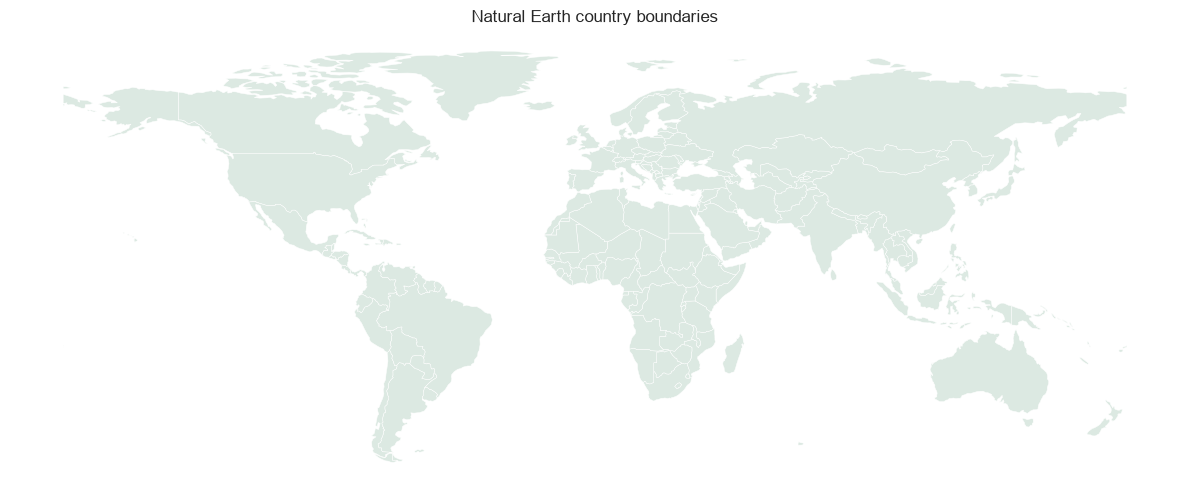

In [3]:
fig, ax = plt.subplots(figsize=(12, 6))
world.plot(ax=ax, color="#dce9e2", edgecolor="white", linewidth=0.35)
ax.set(title="Natural Earth country boundaries", aspect="equal")
ax.axis("off")
fig.tight_layout()
plt.show()

In [4]:
def plot_choropleth(frame, column, title, colorbar_label, cmap="YlOrRd"):
    values = frame[column].dropna()
    upper_limit = values.quantile(0.98)
    normalized_values = frame[column].clip(upper=upper_limit)

    fig, ax = plt.subplots(figsize=(12, 6))
    frame.assign(plot_value=normalized_values).plot(
        column="plot_value",
        ax=ax,
        cmap=cmap,
        edgecolor="white",
        linewidth=0.35,
        legend=True,
        legend_kwds={"label": colorbar_label, "shrink": 0.65},
        missing_kwds={"color": "#d9d9d9", "label": "No matched data"},
    )
    ax.set_title(title, fontsize=16, pad=12)
    ax.axis("off")
    fig.tight_layout()
    return fig, ax

In [5]:
unmatched = world.loc[world["total_cases"].isna(), ["country", "iso3", "continent"]]
print(f"Unmatched map geometries: {len(unmatched)}")
unmatched.reset_index(drop=True)

Unmatched map geometries: 12


,country,iso3,continent
0,Western Sahara,SAH,Africa
1,Falkland Islands,FLK,South America
2,Greenland,GRL,North America
3,French Southern and Antarctic Lands,ATF,Seven seas (open ocean)
4,Puerto Rico,PRI,North America
5,Palestine,PSX,Asia
6,Turkmenistan,TKM,Asia
7,New Caledonia,NCL,Oceania
8,Northern Cyprus,CYN,Asia
9,Somaliland,SOL,Africa


# Step #3 Create a World Choropleth

The map shows newly reported confirmed cases during December 2022 per 100,000 residents. Normalization makes countries with different population sizes more comparable. Values above the 98th percentile share the darkest color so extreme observations do not flatten the rest of the scale.

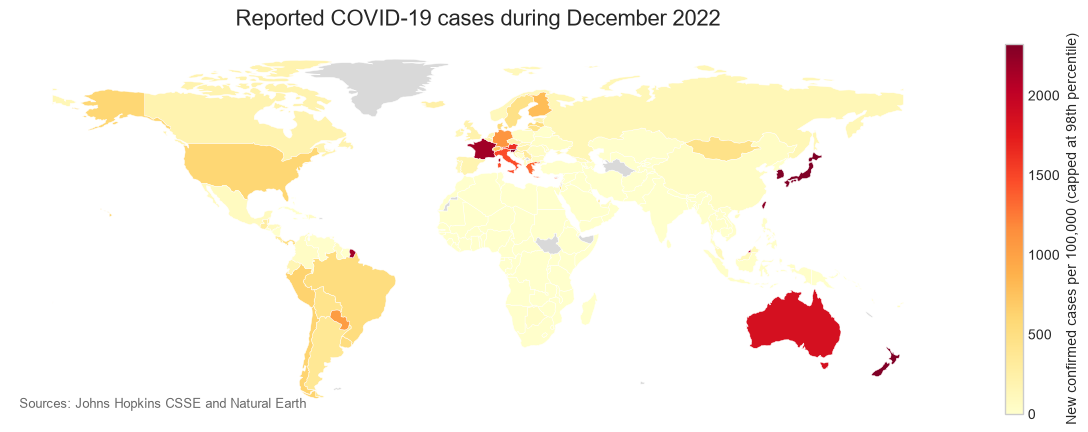

In [6]:
world_figure, world_axis = plot_choropleth(
    world,
    column="new_cases_december_per_100k",
    title="Reported COVID-19 cases during December 2022",
    colorbar_label="New confirmed cases per 100,000 (capped at 98th percentile)",
 )
world_axis.text(
    0.01,
    0.02,
    "Sources: Johns Hopkins CSSE and Natural Earth",
    transform=world_axis.transAxes,
    fontsize=9,
    color="dimgray",
 )
plt.show()

In [7]:
world.nlargest(10, "new_cases_december_per_100k")[
    ["country", "new_cases_december", "new_cases_december_per_100k"]
] .reset_index(drop=True).style.format(
    {
        "new_cases_december": "{:,.0f}",
        "new_cases_december_per_100k": "{:,.1f}",
    }
)

,country,new_cases_december,new_cases_december_per_100k
0,South Korea,"1,960,987","3,792.3"
1,Japan,"4,419,369","3,500.1"
2,New Zealand,"149,602","3,042.5"
3,Slovenia,"48,996","2,346.6"
4,Taiwan,"533,994","2,265.7"
5,France,"1,451,740","2,164.8"
6,Brunei,"8,898","2,053.6"
7,Australia,"471,809","1,860.1"
8,Austria,"143,460","1,616.1"
9,Italy,"883,045","1,464.5"


# Step #4 Zoom In on Africa

Filtering a GeoDataFrame works like filtering a pandas DataFrame. The Africa map uses cumulative confirmed cases per 100,000 through December 31, 2022.

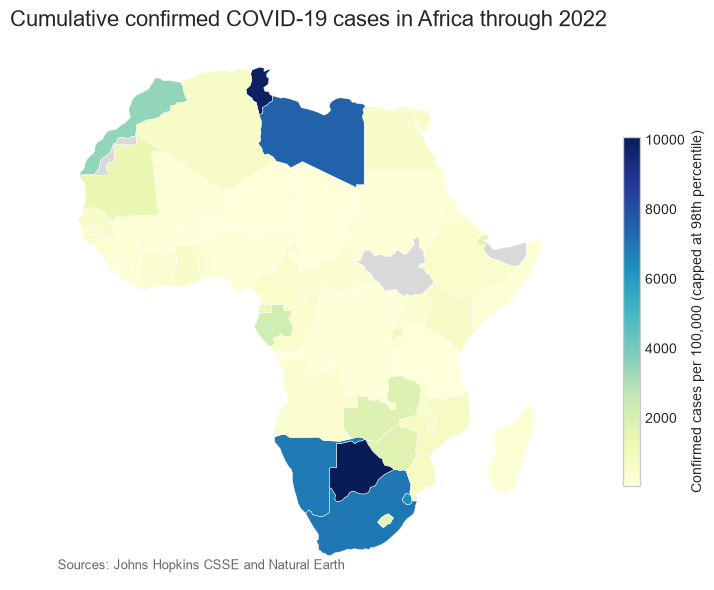

In [8]:
africa = world.loc[world["continent"] == "Africa"].copy()

africa_figure, africa_axis = plot_choropleth(
    africa,
    column="cases_per_100k",
    title="Cumulative confirmed COVID-19 cases in Africa through 2022",
    colorbar_label="Confirmed cases per 100,000 (capped at 98th percentile)",
    cmap="YlGnBu",
 )
africa_axis.text(
    0.01,
    0.02,
    "Sources: Johns Hopkins CSSE and Natural Earth",
    transform=africa_axis.transAxes,
    fontsize=9,
    color="dimgray",
 )
plt.show()

In [9]:
africa.nlargest(10, "cases_per_100k")[
    ["country", "total_cases", "cases_per_100k"]
] .reset_index(drop=True).style.format(
    {"total_cases": "{:,.0f}", "cases_per_100k": "{:,.1f}"}
)

,country,total_cases,cases_per_100k
0,Botswana,"327,860","14,231.9"
1,Tunisia,"1,147,571","9,812.7"
2,Libya,"507,142","7,482.8"
3,South Africa,"4,049,202","6,914.8"
4,Namibia,"170,295","6,826.7"
5,eSwatini,"74,021","6,447.1"
6,Morocco,"1,271,595","3,486.5"
7,Gabon,"48,980","2,254.5"
8,Zambia,"334,425","1,872.4"
9,Zimbabwe,"259,981","1,775.2"


# Step #5 Zoom In on Europe

The Europe view applies the December-incidence metric from the world map. A shared definition makes regional comparisons reproducible, although each map caps colors using its own 98th percentile.

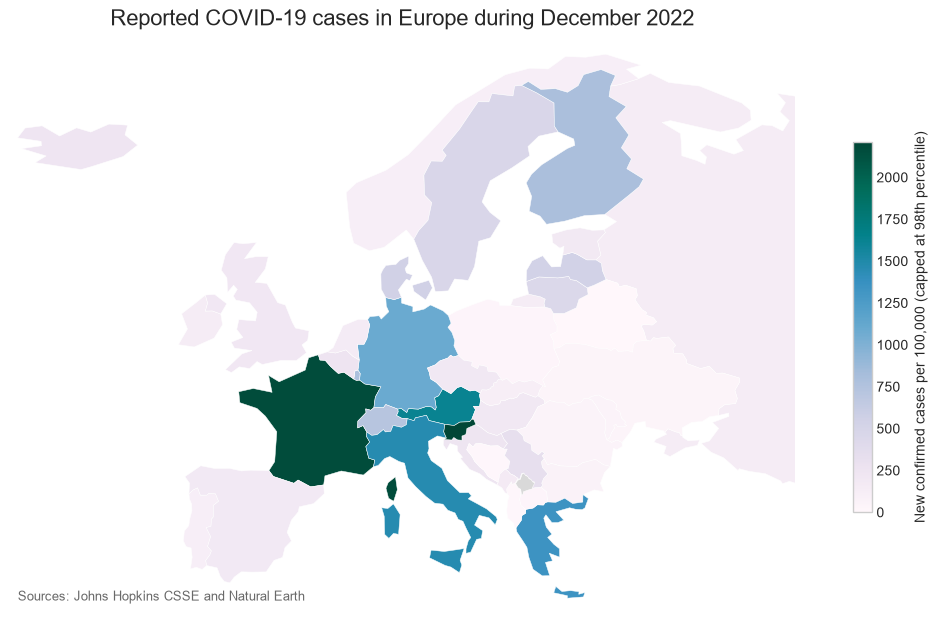

In [10]:
europe = world.loc[world["continent"] == "Europe"].copy()

europe_figure, europe_axis = plot_choropleth(
    europe,
    column="new_cases_december_per_100k",
    title="Reported COVID-19 cases in Europe during December 2022",
    colorbar_label="New confirmed cases per 100,000 (capped at 98th percentile)",
    cmap="PuBuGn",
 )
europe_axis.set_xlim(-25, 45)
europe_axis.set_ylim(34, 72)
europe_axis.text(
    0.01,
    0.02,
    "Sources: Johns Hopkins CSSE and Natural Earth",
    transform=europe_axis.transAxes,
    fontsize=9,
    color="dimgray",
 )
plt.show()

## Interpretation and Limitations

The maps describe reported confirmed cases in an archived dataset. They do not measure all infections: testing access, reporting practices, revisions, and country definitions differ. Natural Earth's population estimates provide an approximate denominator, and unmatched geometries remain gray.

Choropleths emphasize large geographic areas visually, even when their populations are small. Always pair a map with a ranked table, state the unit and period, use a perceptually ordered color map, and disclose any clipping or transformation applied to the color scale.

In [11]:
europe.nlargest(10, "new_cases_december_per_100k")[
    ["country", "new_cases_december", "new_cases_december_per_100k"]
] .reset_index(drop=True).style.format(
    {
        "new_cases_december": "{:,.0f}",
        "new_cases_december_per_100k": "{:,.1f}",
    }
)

,country,new_cases_december,new_cases_december_per_100k
0,Slovenia,"48,996","2,346.6"
1,France,"1,451,740","2,164.8"
2,Austria,"143,460","1,616.1"
3,Italy,"883,045","1,464.5"
4,Greece,"143,797","1,341.9"
5,Germany,"906,381","1,090.3"
6,Finland,"43,951",796.2
7,Luxembourg,"4,903",790.9
8,Switzerland,"61,533",717.6
9,Denmark,"32,136",552.3
